# Práctica: Relación entre Gasto en Salud y PIB per cápita

**Materia:** Tópicos de Big Data

**Objetivo:** combinar (`merge`) los dos indicadores de las prácticas anteriores
(gasto en salud como % del PIB, y PIB per cápita), medir su correlación y revisar
si los países con mayor ingreso destinan una mayor proporción de su PIB a salud.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

OPCIONES_OWID = {"User-Agent": "Our World In Data data fetch/1.0"}

## 1. Cargar ambos datasets

In [2]:
url_salud = (
    "https://ourworldindata.org/grapher/total-healthcare-expenditure-gdp.csv"
    "?v=1&csvType=full&useColumnShortNames=true"
)
url_pib = (
    "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv"
    "?v=1&csvType=full&useColumnShortNames=true"
)

gasto_salud = pd.read_csv(url_salud, storage_options=OPCIONES_OWID)
pib = pd.read_csv(url_pib, storage_options=OPCIONES_OWID)

col_gasto = [c for c in gasto_salud.columns if "health_expenditure" in c][0]
col_pib = [c for c in pib.columns if c.startswith("ny_gdp_pcap")][0]

gasto_salud = gasto_salud.rename(columns={
    "entity": "pais", "code": "codigo", "year": "anio", col_gasto: "gasto_salud_pct_pib",
})
pib = pib.rename(columns={
    "entity": "pais", "code": "codigo", "year": "anio",
    col_pib: "pib_per_capita", "owid_region": "region",
})

## 2. Unir ambos datasets por país, código y año

In [3]:
combinado = pd.merge(
    gasto_salud,
    pib[["pais", "codigo", "anio", "pib_per_capita", "region"]],
    on=["pais", "codigo", "anio"],
    how="inner",
)
print("Dimensiones del dataset combinado:", combinado.shape)
combinado.head()

Dimensiones del dataset combinado: (4430, 6)


,pais,codigo,anio,gasto_salud_pct_pib,pib_per_capita,region
0,Afghanistan,AFG,2002,9.443391,1774.3087,Asia
1,Afghanistan,AFG,2003,8.941258,1815.9282,Asia
2,Afghanistan,AFG,2004,9.808474,1776.9182,Asia
3,Afghanistan,AFG,2005,9.948289,1908.1147,Asia
4,Afghanistan,AFG,2006,10.622766,1929.7239,Asia


## 3. Correlación entre PIB per cápita y gasto en salud

In [4]:
correlacion = combinado[["pib_per_capita", "gasto_salud_pct_pib"]].corr()
correlacion

,pib_per_capita,gasto_salud_pct_pib
pib_per_capita,1.000000,0.193878
gasto_salud_pct_pib,0.193878,1.000000


## 4. Dispersión global (corte 2021)

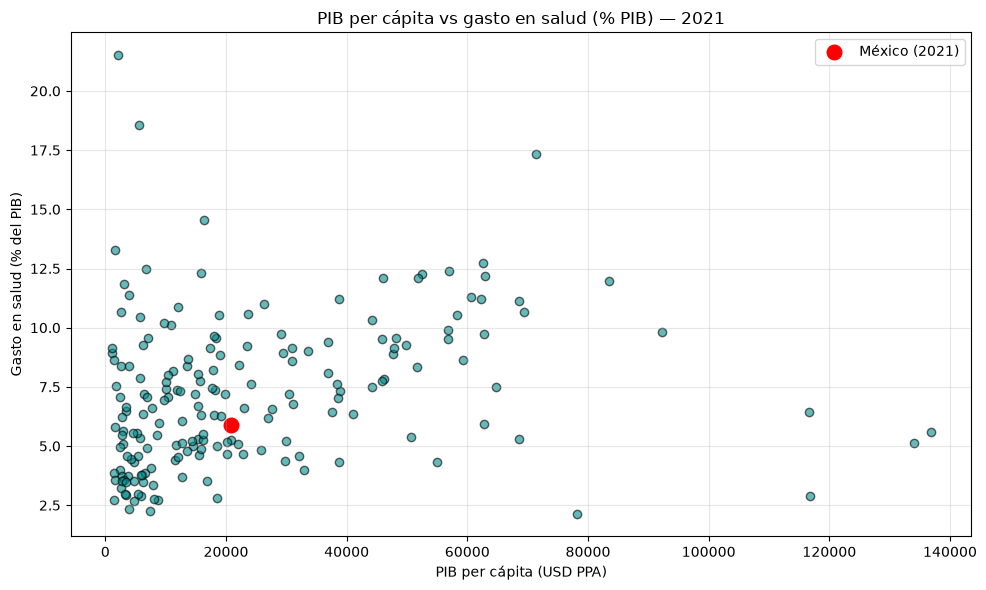

In [5]:
corte_2021 = combinado[combinado["anio"] == 2021].dropna(
    subset=["pib_per_capita", "gasto_salud_pct_pib"]
)

plt.figure(figsize=(10, 6))
plt.scatter(corte_2021["pib_per_capita"], corte_2021["gasto_salud_pct_pib"],
            alpha=0.6, color="darkcyan", edgecolors="k")

mexico_2021 = corte_2021[corte_2021["pais"] == "Mexico"]
if not mexico_2021.empty:
    plt.scatter(mexico_2021["pib_per_capita"], mexico_2021["gasto_salud_pct_pib"],
                color="red", s=110, label="México (2021)")
    plt.legend()

plt.title("PIB per cápita vs gasto en salud (% PIB) — 2021")
plt.xlabel("PIB per cápita (USD PPA)")
plt.ylabel("Gasto en salud (% del PIB)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Trayectoria de México (2000–2023)

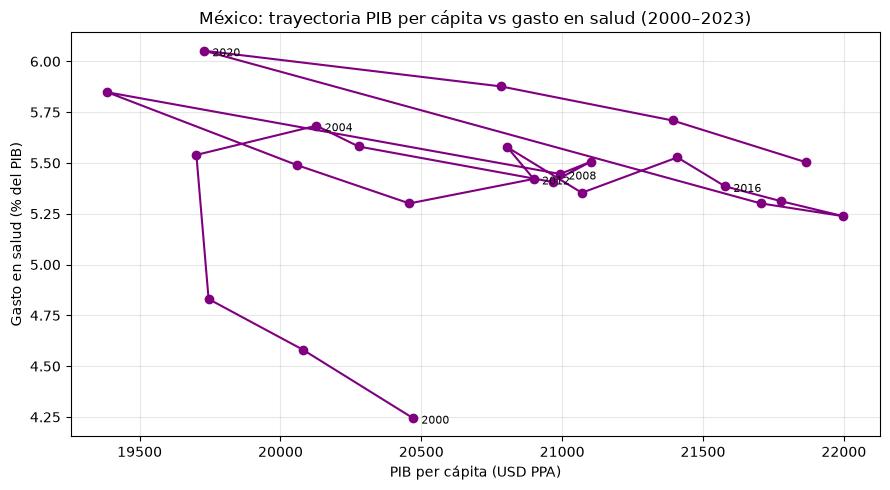

In [6]:
trayectoria_mx = combinado[combinado["pais"] == "Mexico"].sort_values("anio")

plt.figure(figsize=(9, 5))
plt.plot(trayectoria_mx["pib_per_capita"], trayectoria_mx["gasto_salud_pct_pib"],
          marker="o", color="purple")

for _, fila in trayectoria_mx.iloc[::4].iterrows():
    plt.annotate(int(fila["anio"]), (fila["pib_per_capita"], fila["gasto_salud_pct_pib"]),
                 textcoords="offset points", xytext=(6, -4), fontsize=8)

plt.title("México: trayectoria PIB per cápita vs gasto en salud (2000–2023)")
plt.xlabel("PIB per cápita (USD PPA)")
plt.ylabel("Gasto en salud (% del PIB)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Conclusión

La correlación entre PIB per cápita y gasto en salud como % del PIB es positiva
pero débil: tener más ingreso no obliga a un país a gastar una mayor proporción
de su PIB en salud, depende también de su política pública. México se mantiene
relativamente estable alrededor de 5–6% del PIB mientras su PIB per cápita
fluctúa con cada crisis económica (ver la caída de 2009 y 2020).